# Heart Disease: From Clinical Data to Classification

**An exploratory machine learning study of the UCI Cleveland dataset**  
Group A · Anas Ben Zitun, Marwan Elamami, Sanad Ben Latif, Abdul Majed Mraied

This notebook explores a small historical clinical dataset and compares classification approaches. It is an educational exercise, **not a diagnostic or clinical decision tool**. Original Group A analysis has been rebuilt with a reproducible evaluation workflow.

## 1 · The question

Can routinely recorded clinical features distinguish cases with a recorded diagnosis of heart disease from cases without one in this dataset? The original target ranges from 0 to 4; we convert it to **0 = no disease, 1 = disease present**. Predictions concern this dataset's recorded outcome, not a person's future risk.

We reserve a stratified 20% test set once, compare models using stratified cross-validation on the remaining data, and evaluate the selected model once on the held-out test set. All learned preprocessing is fitted within the training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
                             average_precision_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", None)


## 2 · Meet the data

The supplied file contains 13 predictors and a diagnosis field (`num`). The file was included with the original submission; its exact preparation and intermediate source were not documented. The [UCI dataset page](https://archive.ics.uci.edu/dataset/45/heart+disease) describes the source and its CC BY 4.0 terms.

In [2]:
df = pd.read_csv("heart_disease.csv")
expected = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
assert list(df.columns) == expected, "Unexpected dataset schema"
assert df["num"].notna().all()
print(f"Observations: {len(df)} | Predictors: {len(expected) - 1}")
display(df.head())


Observations: 303 | Predictors: 13


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
summary = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
display(summary)
print(f"Duplicate rows: {df.duplicated().sum()}")


,dtype,missing,unique
age,float64,0,41
sex,float64,0,2
cp,float64,0,4
trestbps,float64,0,50
chol,float64,0,152
fbs,float64,0,2
restecg,float64,0,3
thalach,float64,0,91
exang,float64,0,2
oldpeak,float64,0,40


Duplicate rows: 0


### Feature guide

| Field | Meaning | Field | Meaning |
|---|---|---|---|
| `age` | Age in years | `sex` | Sex recorded in dataset |
| `cp` | Chest pain type | `trestbps` | Resting blood pressure |
| `chol` | Serum cholesterol | `fbs` | Fasting blood sugar indicator |
| `restecg` | Resting ECG result | `thalach` | Maximum heart rate |
| `exang` | Exercise-induced angina | `oldpeak` | Exercise-induced ST depression |
| `slope` | Peak exercise ST slope | `ca` | Major vessels colored by fluoroscopy |
| `thal` | Thallium test category | `num` | Recorded diagnosis, 0–4 |

Categorical codes are treated as categories, not as measurements with meaningful numeric distance. Missing values are handled inside each model pipeline.

## 3 · Explore the training data

The split happens **before** exploratory plots or model comparisons. This keeps the test set out of analysis decisions. These descriptive patterns are associations and do not establish causation.

In [4]:
X = df.drop(columns="num")
y = (df["num"] > 0).astype(int).rename("disease")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Training: {len(X_train)} | Held-out test: {len(X_test)}")
print("Training class counts:")
display(y_train.value_counts().rename(index={0: "No disease", 1: "Disease"}).to_frame("count"))


Training: 242 | Held-out test: 61
Training class counts:


,count
disease,
No disease,131
Disease,111


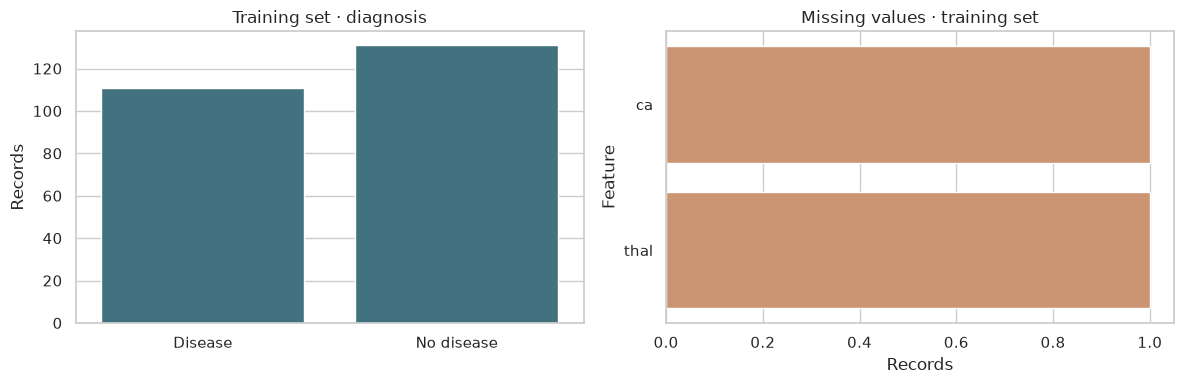

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=y_train.map({0: "No disease", 1: "Disease"}), ax=axes[0], color="#38778a")
axes[0].set(title="Training set · diagnosis", xlabel="", ylabel="Records")
missing = X_train.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    sns.barplot(x=missing.values, y=missing.index, ax=axes[1], color="#d99265")
    axes[1].set(title="Missing values · training set", xlabel="Records", ylabel="Feature")
else:
    axes[1].text(.5, .5, "No missing values", ha="center", va="center", transform=axes[1].transAxes)
    axes[1].set_axis_off()
fig.tight_layout()
plt.show()


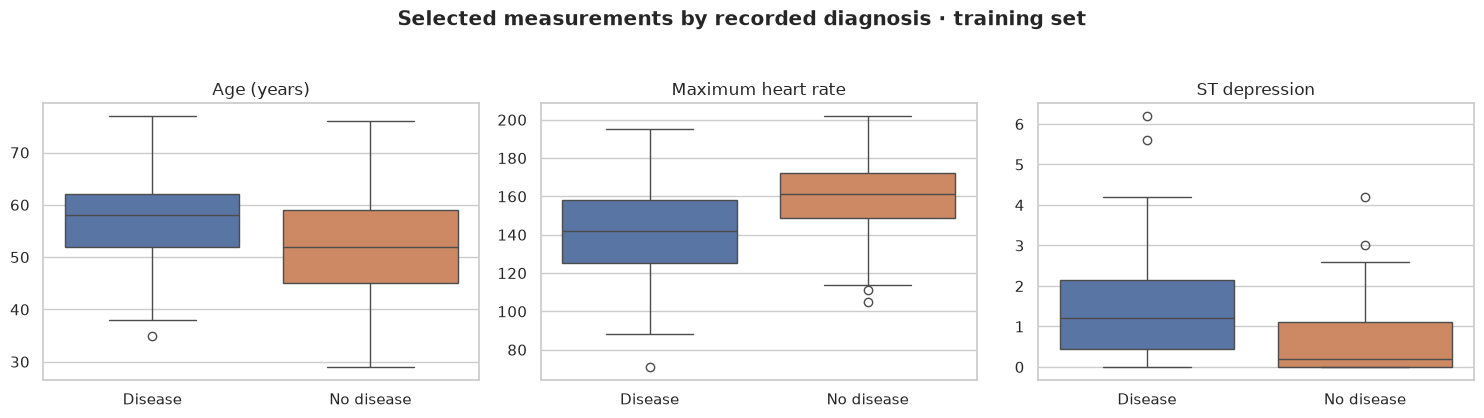

In [6]:
plot_df = X_train.assign(diagnosis=y_train.map({0: "No disease", 1: "Disease"}))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature, label in zip(axes, ["age", "thalach", "oldpeak"], ["Age (years)", "Maximum heart rate", "ST depression"]):
    sns.boxplot(data=plot_df, x="diagnosis", y=feature, hue="diagnosis", legend=False, ax=ax)
    ax.set(title=label, xlabel="", ylabel="")
fig.suptitle("Selected measurements by recorded diagnosis · training set", y=1.04, weight="bold")
fig.tight_layout()
plt.show()


## 4 · Build a leakage-aware comparison

Numerical values receive median imputation and standardization. Categorical values receive most-frequent imputation and one-hot encoding. Each step is inside a `Pipeline`, so cross-validation learns preprocessing only from each training fold. We compare a majority-class baseline, logistic regression, and a random forest.

The selection criterion is **mean cross-validated ROC-AUC** on training data. Recall, precision and F1 provide additional context; the default decision threshold is not optimized for clinical use. No hyperparameter search is performed.

In [7]:
numeric = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "recall": "recall", "precision": "precision", "f1": "f1"}
results = {}
for name, model in models.items():
    pipeline = Pipeline([("preprocess", preprocess), ("model", model)])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, error_score="raise")
    results[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}
    results[name]["roc_auc_std"] = scores["test_roc_auc"].std()
cv_results = pd.DataFrame.from_dict(results, orient="index").sort_values("roc_auc", ascending=False)
display(cv_results.round(3))


/tmp/heart-deps/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/tmp/heart-deps/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/tmp/heart-deps/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/tmp/heart-deps/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to

,roc_auc,accuracy,recall,precision,f1,roc_auc_std
Logistic regression,0.902,0.847,0.783,0.877,0.825,0.014
Random forest,0.894,0.814,0.801,0.797,0.796,0.033
Majority baseline,0.500,0.541,0.000,0.000,0.000,0.000


## 5 · Final held-out evaluation

Choose the highest mean cross-validated ROC-AUC, refit that pipeline on the complete training set, then evaluate on the untouched test set. A small test set produces uncertain estimates; these values should not be read as evidence of clinical performance.

Selected by training cross-validation: Logistic regression
              precision    recall  f1-score   support

  No disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Held-out ROC-AUC: 0.966
Held-out average precision: 0.963


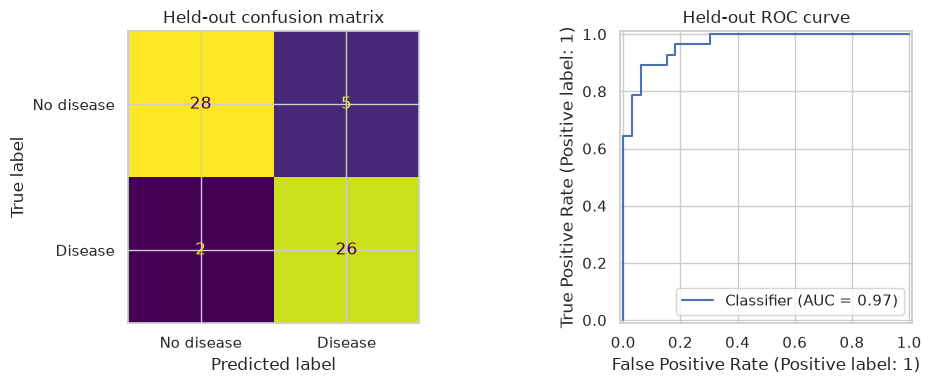

In [8]:
selected_name = cv_results.index[0]
final_model = Pipeline([("preprocess", preprocess), ("model", models[selected_name])])
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_score = final_model.predict_proba(X_test)[:, 1]
print(f"Selected by training cross-validation: {selected_name}")
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"], zero_division=0))
print(f"Held-out ROC-AUC: {roc_auc_score(y_test, y_score):.3f}")
print(f"Held-out average precision: {average_precision_score(y_test, y_score):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No disease", "Disease"], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[1])
axes[0].set_title("Held-out confusion matrix")
axes[1].set_title("Held-out ROC curve")
fig.tight_layout()
plt.show()


## 6 · Interpretation and next steps

The tables and plots above report the result of this specific split and model comparison; they do not establish clinical usefulness. A stronger study would repeat the analysis across multiple splits, report uncertainty and calibration, assess subgroup performance, and validate on an independent contemporary cohort. Decisions about thresholds and clinical utility require domain expertise and prospective validation.

**Dataset citation:** Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989). *Heart Disease* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X. Licensed by UCI under CC BY 4.0. The provided CSV's intermediary provenance is unknown.